In [ ]:
from pydantic import BaseModel, Field
from typing import Annotated, Optional

from IPython.display import Image, display

from langgraph.graph import StateGraph, START, END

In [7]:
class AgentState(BaseModel):
    number_1: Annotated[int, Field(description="First integer")]
    number_2: Annotated[int, Field(description="Second integer")]
    operation: Annotated[str, Field(
            description="Mathematical operator"
        )]
    finalNumber: Annotated[Optional[int], Field(
            description="Final result",
            default=None
        )] 

In [8]:
def adder(state: AgentState) -> AgentState:
    """
    Adds 2 integers
    """

    state.finalNumber = state.number_1 + state.number_2

    return state


def subtractor(state: AgentState) -> AgentState:
    """
    Subtracts the second integer from the first one
    """

    state.finalNumber = state.number_1 - state.number_2

    return state


def decideNextNode(state: AgentState) -> AgentState:
    """
    Selects the next node of the graph to execute
    """

    if state.operation == "+":
        # returns the name of the edge
        return "additionOperation"
    else:
        return "subtractionOperation"

In [ ]:
graph = StateGraph(AgentState)

graph.add_node("addNode", adder)
graph.add_node("subtractNode", subtractor)

"""
the following works like a PassThrough runnable, that is, whatever it 
takes as input, it spits out the same as output; we cannot directly use 
'decideNextNode' as a node here, since, in that function, we're not 
returning the updated state unlike the other 2 functions
"""
graph.add_node("router", lambda state: state)

graph.add_edge(START, "router")

"""
the following goes like this:
1. source (router)
2. path (decideNextNode)
3. path map (the dictionary)
"""
graph.add_conditional_edges(
    "router",
    decideNextNode,  # for the edges
    {
        # in the format - "Edge name": "Node name"
        "additionOperation": "addNode",
        "subtractionOperation": "subtractNode"
    }
)

graph.add_edge("addNode", END)
graph.add_edge("subtractNode", END)

app = graph.compile()

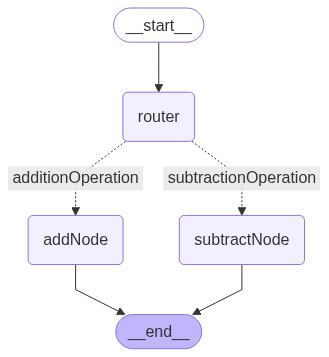

In [10]:
display(Image(app.get_graph().draw_mermaid_png()))

In [12]:
"""
The following is a different approach for invoking the graph (by 
creating objects of the schema class)
"""
paramterList_1 = AgentState(
    number_1=9,
    number_2=5,
    operation="-"
)

paramterList_2 = AgentState(
    number_1=9,
    number_2=5,
    operation="+"
)

In [13]:
result_1 = app.invoke(paramterList_1)
result_1

{'number_1': 9, 'number_2': 5, 'operation': '-', 'finalNumber': 4}

In [14]:
result_2 = app.invoke(paramterList_2)
result_2

{'number_1': 9, 'number_2': 5, 'operation': '+', 'finalNumber': 14}